In [23]:
import pandas as pd

df = pd.read_csv("data/diabetes_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (100000, 31)


,age,gender,ethnicity,education_level,income_level,employment_status,smoking_status,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,...,hdl_cholesterol,ldl_cholesterol,triglycerides,glucose_fasting,glucose_postprandial,insulin_level,hba1c,diabetes_risk_score,diabetes_stage,diagnosed_diabetes
0,58,Male,Asian,Highschool,Lower-Middle,Employed,Never,0,215,5.7,...,41,160,145,136,236,6.36,8.18,29.6,Type 2,1
1,48,Female,White,Highschool,Middle,Employed,Former,1,143,6.7,...,55,50,30,93,150,2.00,5.63,23.0,No Diabetes,0
2,60,Male,Hispanic,Highschool,Middle,Unemployed,Never,1,57,6.4,...,66,99,36,118,195,5.07,7.51,44.7,Type 2,1
3,74,Female,Black,Highschool,Low,Retired,Never,0,49,3.4,...,50,79,140,139,253,5.28,9.03,38.2,Type 2,1
4,46,Male,White,Graduate,Middle,Retired,Never,1,109,7.2,...,52,125,160,137,184,12.74,7.20,23.5,Type 2,1


In [24]:
print("Total rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

Total rows and columns: (100000, 31)

Column names:
['age', 'gender', 'ethnicity', 'education_level', 'income_level', 'employment_status', 'smoking_status', 'alcohol_consumption_per_week', 'physical_activity_minutes_per_week', 'diet_score', 'sleep_hours_per_day', 'screen_time_hours_per_day', 'family_history_diabetes', 'hypertension_history', 'cardiovascular_history', 'bmi', 'waist_to_hip_ratio', 'systolic_bp', 'diastolic_bp', 'heart_rate', 'cholesterol_total', 'hdl_cholesterol', 'ldl_cholesterol', 'triglycerides', 'glucose_fasting', 'glucose_postprandial', 'insulin_level', 'hba1c', 'diabetes_risk_score', 'diabetes_stage', 'diagnosed_diabetes']


In [25]:
print("Missing values in each column:")

print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
age                                   0
gender                                0
ethnicity                             0
education_level                       0
income_level                          0
employment_status                     0
smoking_status                        0
alcohol_consumption_per_week          0
physical_activity_minutes_per_week    0
diet_score                            0
sleep_hours_per_day                   0
screen_time_hours_per_day             0
family_history_diabetes               0
hypertension_history                  0
cardiovascular_history                0
bmi                                   0
waist_to_hip_ratio                    0
systolic_bp                           0
diastolic_bp                          0
heart_rate                            0
cholesterol_total                     0
hdl_cholesterol                       0
ldl_cholesterol                       0
triglycerides                         0
glucose_f

In [26]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [27]:
print("Diabetes diagnosis distribution:")
print(df["diagnosed_diabetes"].value_counts())

print("\nPercentage distribution:")
print(
    df["diagnosed_diabetes"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Diabetes diagnosis distribution:
diagnosed_diabetes
1    59998
0    40002
Name: count, dtype: int64

Percentage distribution:
diagnosed_diabetes
1    60.0
0    40.0
Name: proportion, dtype: float64


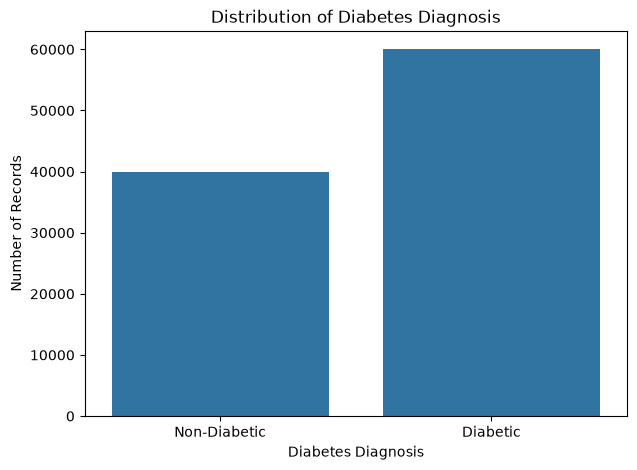

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="diagnosed_diabetes"
)

plt.title("Distribution of Diabetes Diagnosis")
plt.xlabel("Diabetes Diagnosis")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["Non-Diabetic", "Diabetic"])

plt.show()

In [29]:
features = [
    "age",
    "bmi",
    "systolic_bp",
    "diastolic_bp",
    "glucose_fasting",
    "glucose_postprandial",
    "hba1c"
]

display(df[features].describe().round(2))

,age,bmi,systolic_bp,diastolic_bp,glucose_fasting,glucose_postprandial,hba1c
count,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00
mean,50.12,25.61,115.80,75.23,111.12,160.04,6.52
std,15.60,3.59,14.28,8.20,13.60,30.94,0.81
min,18.00,15.00,90.00,50.00,60.00,70.00,4.00
25%,39.00,23.20,106.00,70.00,102.00,139.00,5.97
50%,50.00,25.60,116.00,75.00,111.00,160.00,6.52
75%,61.00,28.00,125.00,81.00,120.00,181.00,7.07
max,90.00,39.20,179.00,110.00,172.00,287.00,9.80


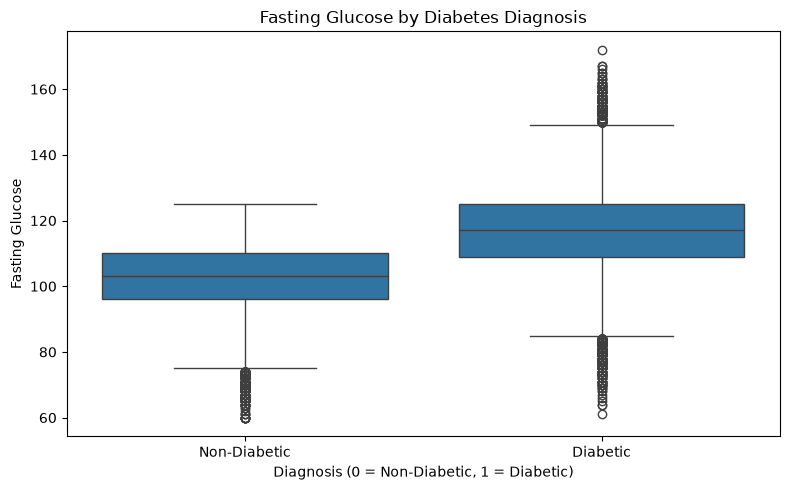

In [30]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="diagnosed_diabetes",
    y="glucose_fasting"
)

plt.title("Fasting Glucose by Diabetes Diagnosis")
plt.xlabel("Diagnosis (0 = Non-Diabetic, 1 = Diabetic)")
plt.ylabel("Fasting Glucose")

plt.xticks([0, 1], ["Non-Diabetic", "Diabetic"])
plt.tight_layout()
plt.show()

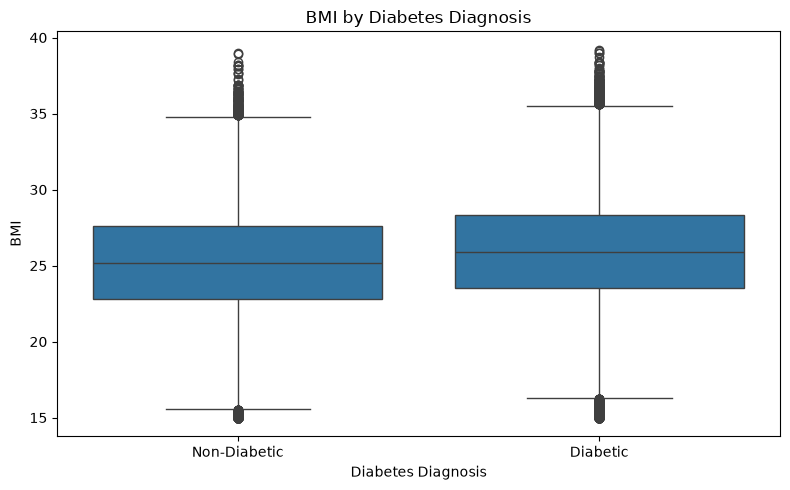

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="diagnosed_diabetes",
    y="bmi"
)

plt.title("BMI by Diabetes Diagnosis")
plt.xlabel("Diabetes Diagnosis")
plt.ylabel("BMI")

plt.xticks([0, 1], ["Non-Diabetic", "Diabetic"])
plt.tight_layout()
plt.show()

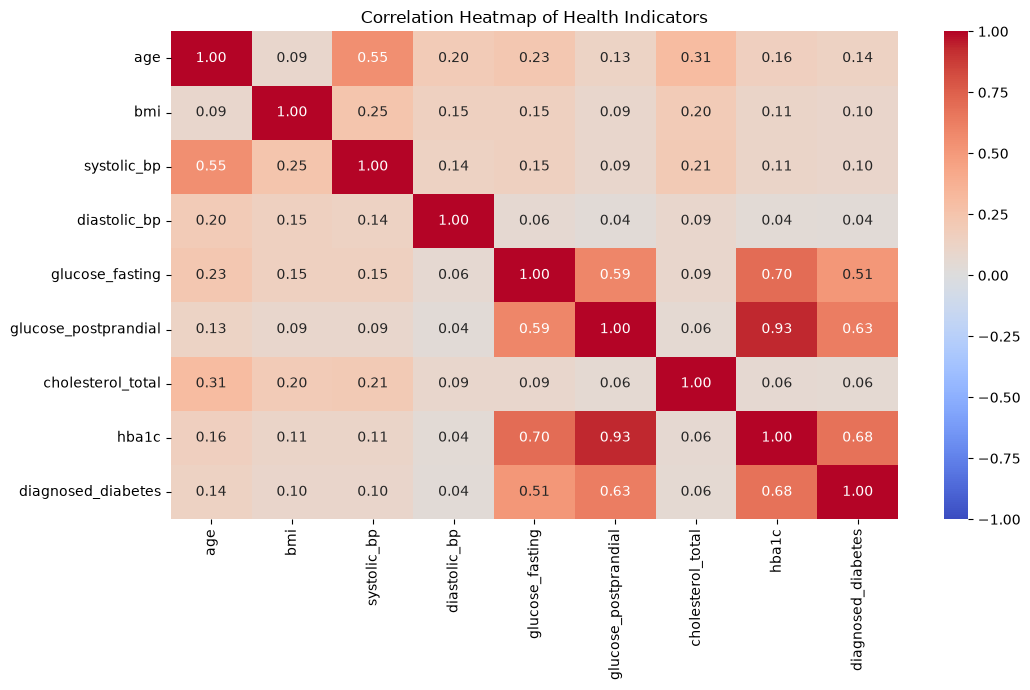

In [32]:
features = [
    "age",
    "bmi",
    "systolic_bp",
    "diastolic_bp",
    "glucose_fasting",
    "glucose_postprandial",
    "cholesterol_total",
    "hba1c",
    "diagnosed_diabetes"
]

plt.figure(figsize=(11, 7))

correlation = df[features].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Health Indicators")
plt.tight_layout()
plt.show()

In [33]:
print("Categorical columns:\n")

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print(categorical_columns)

print("\nNumber of unique values in each categorical column:\n")

for col in categorical_columns:
    print(f"{col}: {df[col].nunique()} unique values")

Categorical columns:

['gender', 'ethnicity', 'education_level', 'income_level', 'employment_status', 'smoking_status', 'diabetes_stage']

Number of unique values in each categorical column:



C:\Users\SHAILESH PATIL\AppData\Local\Temp\ipykernel_17196\3584142813.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


gender: 3 unique values
ethnicity: 5 unique values
education_level: 4 unique values
income_level: 5 unique values
employment_status: 4 unique values
smoking_status: 3 unique values
diabetes_stage: 5 unique values


In [34]:
print(pd.crosstab(
    df["diabetes_stage"],
    df["diagnosed_diabetes"],
    normalize="index"
).round(3))

diagnosed_diabetes      0      1
diabetes_stage                  
Gestational         0.432  0.568
No Diabetes         1.000  0.000
Pre-Diabetes        1.000  0.000
Type 1              0.459  0.541
Type 2              0.000  1.000


In [35]:
# Target variable
y = df["diagnosed_diabetes"]

# Remove columns that could leak the answer
X = df.drop(
    columns=[
        "diagnosed_diabetes",
        "diabetes_stage",
        "diabetes_risk_score"
    ]
)

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nRemaining input columns:")
print(X.columns.tolist())

Input features shape: (100000, 28)
Target shape: (100000,)

Remaining input columns:
['age', 'gender', 'ethnicity', 'education_level', 'income_level', 'employment_status', 'smoking_status', 'alcohol_consumption_per_week', 'physical_activity_minutes_per_week', 'diet_score', 'sleep_hours_per_day', 'screen_time_hours_per_day', 'family_history_diabetes', 'hypertension_history', 'cardiovascular_history', 'bmi', 'waist_to_hip_ratio', 'systolic_bp', 'diastolic_bp', 'heart_rate', 'cholesterol_total', 'hdl_cholesterol', 'ldl_cholesterol', 'triglycerides', 'glucose_fasting', 'glucose_postprandial', 'insulin_level', 'hba1c']


In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (80000, 28)
Testing features: (20000, 28)

Training target distribution:
diagnosed_diabetes
1    47998
0    32002
Name: count, dtype: int64

Testing target distribution:
diagnosed_diabetes
1    12000
0     8000
Name: count, dtype: int64


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "gender",
    "ethnicity",
    "education_level",
    "income_level",
    "employment_status",
    "smoking_status"
]

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("numerical", "passthrough", numerical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Encoding completed successfully!")

Processed training shape: (80000, 46)
Processed testing shape: (20000, 46)
Encoding completed successfully!


In [38]:
from sklearn.ensemble import RandomForestClassifier
import time

# Create the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
start_time = time.time()

rf_model.fit(X_train_processed, y_train)

training_time = time.time() - start_time

print("Random Forest training completed!")
print(f"Training time: {training_time:.2f} seconds")

Random Forest training completed!
Training time: 5.32 seconds


In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Make predictions
y_pred = rf_model.predict(X_test_processed)

# Get predicted probabilities
y_prob = rf_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
print("Model Evaluation Results")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Evaluation Results
-----------------------------------
Accuracy:  0.9196
Precision: 0.9994
Recall:    0.8665
F1-Score:  0.9282
ROC-AUC:   0.9413

Classification Report:
              precision    recall  f1-score   support

           0       0.83      1.00      0.91      8000
           1       1.00      0.87      0.93     12000

    accuracy                           0.92     20000
   macro avg       0.92      0.93      0.92     20000
weighted avg       0.93      0.92      0.92     20000



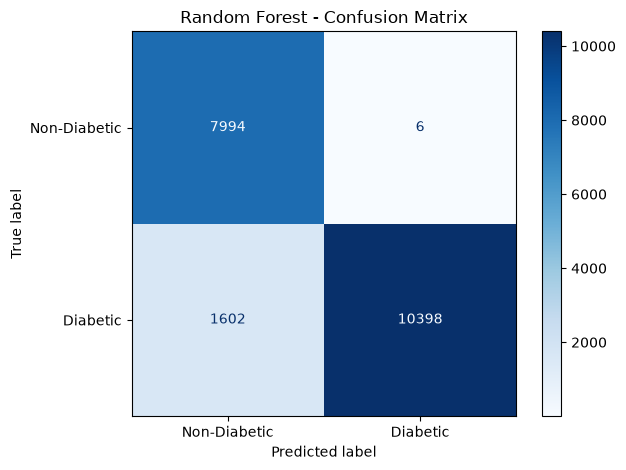

Confusion Matrix:
[[ 7994     6]
 [ 1602 10398]]


In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Diabetic", "Diabetic"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

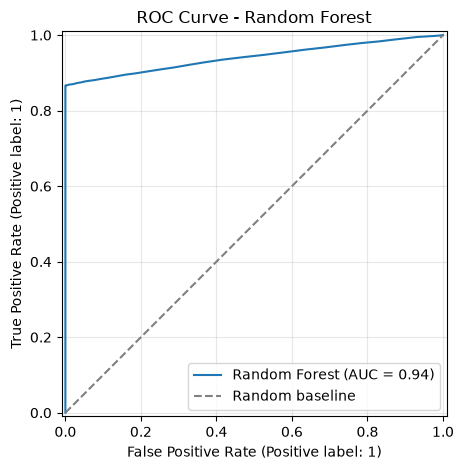

In [41]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random baseline"
)

plt.title("ROC Curve - Random Forest")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

                                          Feature  Importance
45                               numerical__hba1c    0.421151
43                numerical__glucose_postprandial    0.189637
42                     numerical__glucose_fasting    0.102050
26  numerical__physical_activity_minutes_per_week    0.017742
24                                 numerical__age    0.016990
33                                 numerical__bmi    0.016076
41                       numerical__triglycerides    0.015568
44                       numerical__insulin_level    0.015060
38                   numerical__cholesterol_total    0.014788
29           numerical__screen_time_hours_per_day    0.014743
27                          numerical__diet_score    0.014539
35                         numerical__systolic_bp    0.014474
28                 numerical__sleep_hours_per_day    0.014246
40                     numerical__ldl_cholesterol    0.014163
39                     numerical__hdl_cholesterol    0.014133


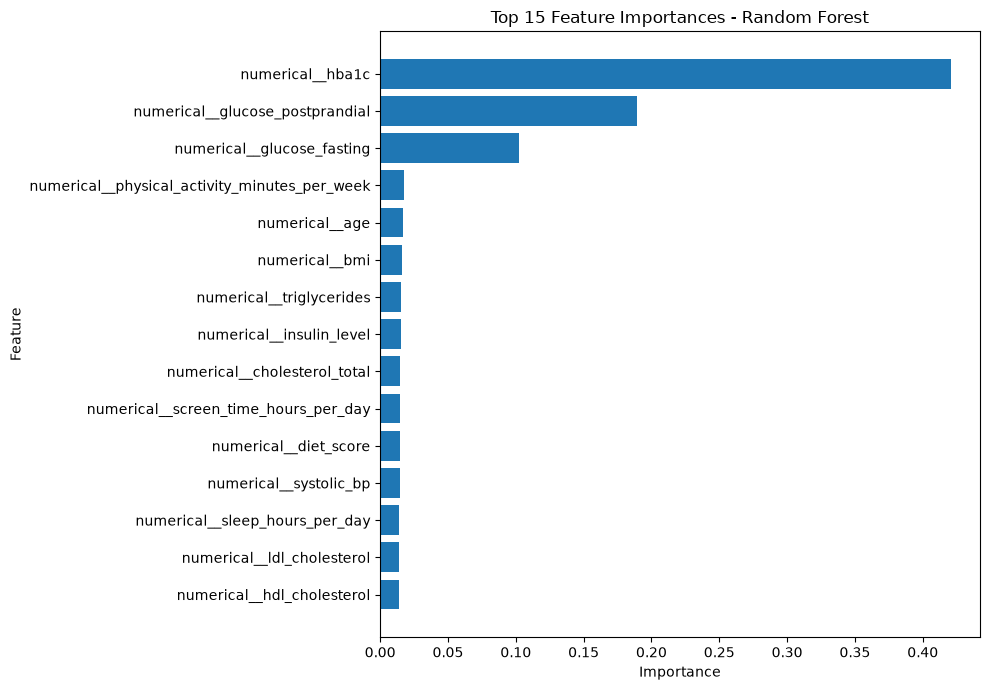

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after one-hot encoding
feature_names = preprocessor.get_feature_names_out()

# Extract Random Forest feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Show the 15 most important features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

print(importance_df)

# Plot feature importance
plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)

plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [45]:
import os
import joblib

print("Current notebook working directory:", os.getcwd())

# Create models folder in the current working directory
os.makedirs("models", exist_ok=True)

# Save both files
joblib.dump(rf_model, "models/diabetes_model.pkl")
joblib.dump(preprocessor, "models/diabetes_preprocessor.pkl")

print("\nFiles saved:")
print(os.listdir("models"))

Current notebook working directory: C:\Users\SHAILESH PATIL\Desktop\Diabetes-Prediction-System

Files saved:
['diabetes_model.pkl', 'diabetes_preprocessor.pkl']


In [3]:
import pandas as pd

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ]
})

results["Score"] = results["Score"].round(4)

results.to_csv("evaluation_results.csv", index=False)

display(results)

print("Evaluation results saved successfully!")

NameError: name 'y_test' is not defined

In [4]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [1]:
import os

print("Current folder:", os.getcwd())
print(os.listdir())

Current folder: C:\Users\SHAILESH PATIL\Desktop\Diabetes-Prediction-System
['.ipynb_checkpoints', 'app.py', 'data', 'diabetes_prediction.ipynb', 'models']


In [2]:
import pandas as pd
import os

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ]
})

results["Score"] = results["Score"].round(4)

file_path = os.path.join(os.getcwd(), "evaluation_results.csv")
results.to_csv(file_path, index=False)

display(results)
print("Saved to:", file_path)

NameError: name 'accuracy_score' is not defined

In [3]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Metrics imported successfully!")

Metrics imported successfully!


In [4]:
print("y_test exists:", "y_test" in globals())
print("y_pred exists:", "y_pred" in globals())
print("y_prob exists:", "y_prob" in globals())

y_test exists: False
y_pred exists: False
y_prob exists: False


In [5]:
print("Model exists:", "rf_model" in globals())
print("Preprocessor exists:", "preprocessor" in globals())
print("X_test exists:", "X_test" in globals())

Model exists: False
Preprocessor exists: False
X_test exists: False


In [6]:
import joblib
import os

model_path = "models/diabetes_model.pkl"
preprocessor_path = "models/diabetes_preprocessor.pkl"

print("Model file exists:", os.path.exists(model_path))
print("Preprocessor file exists:", os.path.exists(preprocessor_path))

Model file exists: True
Preprocessor file exists: True


In [7]:
import joblib

rf_model = joblib.load("models/diabetes_model.pkl")
preprocessor = joblib.load("models/diabetes_preprocessor.pkl")

print("Model loaded successfully!")
print("Preprocessor loaded successfully!")

Model loaded successfully!
Preprocessor loaded successfully!


In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/diabetes_dataset.csv")

# Remove columns that could cause target leakage
X = df.drop(
    columns=["diagnosed_diabetes", "diabetes_stage", "diabetes_risk_score"]
)
y = df["diagnosed_diabetes"]

# Recreate the original train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Test data restored!")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

Test data restored!
X_test shape: (20000, 28)
y_test shape: (20000,)


In [9]:
# Transform test data and generate predictions
X_test_processed = preprocessor.transform(X_test)

y_pred = rf_model.predict(X_test_processed)
y_prob = rf_model.predict_proba(X_test_processed)[:, 1]

print("Predictions generated successfully!")
print("Total predictions:", len(y_pred))
print("Probability values:", len(y_prob))

Predictions generated successfully!
Total predictions: 20000
Probability values: 20000


In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd
import os

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ]
})

results["Score"] = results["Score"].round(4)

file_path = os.path.join(os.getcwd(), "evaluation_results.csv")
results.to_csv(file_path, index=False)

display(results)
print("\nFile saved successfully!")
print("Location:", file_path)

,Metric,Score
0,Accuracy,0.9196
1,Precision,0.9994
2,Recall,0.8665
3,F1-Score,0.9282
4,ROC-AUC,0.9413



File saved successfully!
Location: C:\Users\SHAILESH PATIL\Desktop\Diabetes-Prediction-System\evaluation_results.csv


In [11]:
import os

for folder, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".venv", ".ipynb_checkpoints", "__pycache__"]]
    print(f"\nFolder: {folder}")
    for file in files:
        print("  ", file)


Folder: .
   app.py
   diabetes_prediction.ipynb
   evaluation_results.csv
   README.md

Folder: .\data
   diabetes_dataset.csv

Folder: .\models
   diabetes_model.pkl
   diabetes_preprocessor.pkl


In [12]:
%%writefile requirements.txt
pandas
numpy
scikit-learn
joblib
streamlit
matplotlib
seaborn

Writing requirements.txt


In [13]:
import os

print("requirements.txt exists:", os.path.exists("requirements.txt"))

with open("requirements.txt", "r") as file:
    print(file.read())

requirements.txt exists: True
pandas
numpy
scikit-learn
joblib
streamlit
matplotlib
seaborn

